# Vibe Quest S13 · ¿Qué pasa con un Transformer sin Positional Encoding?
**Pregunta 2 (Clase 12):** si quitamos el Positional Encoding (PE), "El gato persiguió al perro" y "El perro persiguió al gato" ¿producen lo mismo? Lo demuestro con código en PyTorch, comparo los embeddings de salida con y sin PE y visualizo por qué se pierde el orden.

**Hipótesis (Clase 12, lámina 120):** la self-attention no distingue el orden; sin PE, permutar las palabras solo permuta las filas de la salida.

El notebook tiene dos partes:
- **Parte A · Demostración estructural (sección 2):** un codificador con pesos aleatorios y semilla fija, aplicado a las frases de la consigna. Muestra la propiedad sin entrenar nada.
- **Parte B · Transformer entrenado con datos reales (sección 3):** oraciones de Tatoeba (español-inglés). Sigue la metodología de las fuentes: el mismo modelo variando solo el PE, atención bidireccional frente a causal, una tarea donde el orden importa y otra donde no, y la ablación del PE en evaluación.

Hay paneles con sliders en las secciones 2.10, 3.14, 3.16 y 3.17.

**Entorno recomendado:** GPU (Entorno de ejecución → Cambiar tipo de entorno → T4). Con GPU todo corre en unos 3 minutos; en CPU, bastante más.

# 1 · Preparación
## 1.1 · Librerías
`torch` para el modelo, `numpy` para generar los pesos con semilla fija (así coinciden con la referencia en NumPy), `pandas` para tablas, `matplotlib` para los gráficos e `ipywidgets` para los sliders. Todo viene instalado en Google Colab.

In [45]:
import itertools
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

torch.set_default_dtype(torch.float64)
print("torch", torch.__version__)

torch 2.14.1+cu130


## 1.2 · Parámetros de la Parte A
- **`D`:** dimensión del embedding (`d_model`). **`CAPAS`:** capas del codificador. **`SEMILLA`:** semilla de los pesos.
- **`FRASE_A` y `FRASE_B`:** las dos frases de la consigna. Tienen las mismas palabras y distinto orden.
- **`FRASES_EXTRA`:** una frase más larga y una con una palabra repetida, para probar que el resultado no depende de las frases de la consigna.

In [46]:
D = 16
CAPAS = 2
SEMILLA = 0
FRASE_A = ["El", "gato", "persiguió", "al", "perro"]
FRASE_B = ["El", "perro", "persiguió", "al", "gato"]
FRASES_EXTRA = {
    "larga_7": ["El", "gato", "negro", "persiguió", "al", "perro", "grande"],
    "repetida": ["El", "gato", "vio", "al", "gato", "gris"],
}
CARPETA_SALIDA = Path("resultados_s13")
CARPETA_SALIDA.mkdir(exist_ok=True)

# 2 · Parte A · Demostración estructural
## 2.1 · Positional Encoding sinusoidal
Es la fórmula de la Clase 12 (lámina 120): `PE(pos, 2i) = sin(pos / 10000^(2i/d))` y `PE(pos, 2i+1) = cos(pos / 10000^(2i/d))`. Cada posición recibe un vector distinto que se suma al embedding de la palabra.

In [47]:
def pe_sinusoidal(n_pos, d):
    pos = torch.arange(n_pos)[:, None].double()
    i = torch.arange(0, d, 2)[None, :].double()
    ang = pos / (10000.0 ** (i / d))
    pe = torch.zeros(n_pos, d)
    pe[:, 0::2] = torch.sin(ang)
    pe[:, 1::2] = torch.cos(ang)
    return pe

## 2.2 · Comprobación contra la fórmula
Calculo a mano algunos valores de la fórmula y verifico que la función los reproduce: en `pos = 0` los senos valen 0 y los cosenos 1, y en `pos = 3`, `i = 1` (d = 8) el seno es `sin(3 / 10000^(2/8))`.

In [48]:
pe_prueba = pe_sinusoidal(10, 8)
assert torch.allclose(pe_prueba[0, 0::2], torch.zeros(4))
assert torch.allclose(pe_prueba[0, 1::2], torch.ones(4))
esperado = np.sin(3 / 10000 ** (2 / 8))
assert abs(pe_prueba[3, 2].item() - esperado) < 1e-12
print("PE(3, 2) =", pe_prueba[3, 2].item(), "| fórmula =", esperado)
print("PE verificado contra la fórmula de la lámina 120")

PE(3, 2) = 0.29552020666133955 | fórmula = 0.29552020666133955
PE verificado contra la fórmula de la lámina 120


## 2.3 · El modelo: un codificador Transformer mínimo
Cada capa hace: self-attention `softmax(QKᵀ/√d)V`, luego `LayerNorm(x + Sublayer(x))` (Add & Norm de la lámina 122) y una red feed-forward con su Add & Norm. Los embeddings de las palabras y los pesos son aleatorios con semilla fija, generados con NumPy para que coincidan con la referencia. Un mismo token tiene **siempre el mismo embedding**, esté donde esté en la frase.

In [49]:
def crear_pesos(d, n_capas, semilla=0):
    rng = np.random.default_rng(semilla)
    d_ff = 4 * d
    capas = []
    for _ in range(n_capas):
        capas.append({
            "Wq": rng.normal(0, d ** -0.5, (d, d)), "Wk": rng.normal(0, d ** -0.5, (d, d)),
            "Wv": rng.normal(0, d ** -0.5, (d, d)), "Wo": rng.normal(0, d ** -0.5, (d, d)),
            "W1": rng.normal(0, d ** -0.5, (d, d_ff)), "W2": rng.normal(0, d_ff ** -0.5, (d_ff, d)),
        })
    return [{k: torch.tensor(v) for k, v in capa.items()} for capa in capas]


def crear_embeddings(vocab, d, semilla=1, escala=1.0):
    rng = np.random.default_rng(semilla)
    return {w: torch.tensor(escala * rng.normal(0, 1, d)) for w in sorted(set(vocab))}


def codificador(x, capas):
    d = x.shape[1]
    atenciones = []
    for p in capas:
        q, k, v = x @ p["Wq"], x @ p["Wk"], x @ p["Wv"]
        a = torch.softmax(q @ k.T / d ** 0.5, dim=-1)
        atenciones.append(a)
        x = F.layer_norm(x + (a @ v) @ p["Wo"], (d,))
        x = F.layer_norm(x + torch.relu(x @ p["W1"]) @ p["W2"], (d,))
    return x, atenciones


def ejecutar(frase, emb, capas, usar_pe, escala_pe=1.0):
    x = torch.stack([emb[w] for w in frase])
    if usar_pe:
        x = x + escala_pe * pe_sinusoidal(len(frase), x.shape[1])
    return codificador(x, capas)

## 2.4 · Medidas que uso
- **Permutación `perm`:** índice de cada palabra de la frase B dentro de la frase A (para B = `[El, perro, persiguió, al, gato]` queda `[0, 4, 2, 3, 1]`).
- **Error de equivarianza:** `max |salida(B) − salida(A)[perm]|`. Si es ~0, la salida de cada palabra no depende de su posición: el modelo solo reordenó las filas.
- **Diferencia de la frase:** `max |media de filas de A − media de filas de B|`. Si es ~0, las dos frases se ven idénticas a un clasificador que promedie los vectores.
- **Coseno de "gato":** similitud entre el vector de salida de "gato" en A (posición 1) y en B (posición 4).

In [50]:
def permutacion(frase_a, frase_b):
    return [frase_a.index(w) for w in frase_b]


def coseno(a, b):
    return (a @ b / (a.norm() * b.norm())).item()


def medir(frase_a, frase_b, emb, capas, usar_pe, escala_pe=1.0):
    perm = permutacion(frase_a, frase_b)
    sa, _ = ejecutar(frase_a, emb, capas, usar_pe, escala_pe)
    sb, _ = ejecutar(frase_b, emb, capas, usar_pe, escala_pe)
    return {
        "error_equivarianza": (sb - sa[perm]).abs().max().item(),
        "dif_promedio_frase": (sa.mean(0) - sb.mean(0)).abs().max().item(),
    }

## 2.5 · Experimento A1 · Las dos frases de la consigna
Ejecuto el mismo modelo, con los mismos pesos, sobre A y B, sin PE y con PE. Si la hipótesis es correcta, sin PE el error de equivarianza y la diferencia de la frase deben ser de orden 1e-15 (ruido de punto flotante).

In [51]:
emb = crear_embeddings(FRASE_A, D)
capas = crear_pesos(D, CAPAS, SEMILLA)
PERM = permutacion(FRASE_A, FRASE_B)
print("perm A → B:", PERM)

filas = []
for usar_pe in (False, True):
    fila = {"usar_pe": usar_pe, **medir(FRASE_A, FRASE_B, emb, capas, usar_pe)}
    sa, _ = ejecutar(FRASE_A, emb, capas, usar_pe)
    sb, _ = ejecutar(FRASE_B, emb, capas, usar_pe)
    fila["cos_gato_A_vs_B"] = coseno(sa[1], sb[4])
    filas.append(fila)
e1 = pd.DataFrame(filas)
display(e1)

perm A → B: [0, 4, 2, 3, 1]


,usar_pe,error_equivarianza,dif_promedio_frase,cos_gato_A_vs_B
0,False,1.332268e-15,4.163336e-16,1.000000
1,True,1.474052e+00,3.611362e-01,0.868572


## 2.6 · Verificación con `assert`
Sin PE: la salida de B es exactamente la de A con las filas reordenadas y el "gato" tiene el mismo vector en las dos frases. Con PE: las salidas difieren de forma clara. Si algo de esto fallara, la celda se detiene.

In [52]:
sin_pe, con_pe = e1.iloc[0], e1.iloc[1]
assert sin_pe.error_equivarianza < 1e-10 and sin_pe.dif_promedio_frase < 1e-10
assert abs(sin_pe.cos_gato_A_vs_B - 1.0) < 1e-10
assert con_pe.error_equivarianza > 0.1 and con_pe.dif_promedio_frase > 0.01
print("Sin PE el orden no deja huella; con PE sí")

Sin PE el orden no deja huella; con PE sí


## 2.7 · Visualización · Matrices de atención de la capa 1
Cada fila es una palabra (la consulta) y cada columna, la palabra a la que atiende. Sin PE, la matriz de B es la de A con filas y columnas reordenadas: nada cambia salvo el orden de las etiquetas. Con PE, la matriz de B ya es otra.

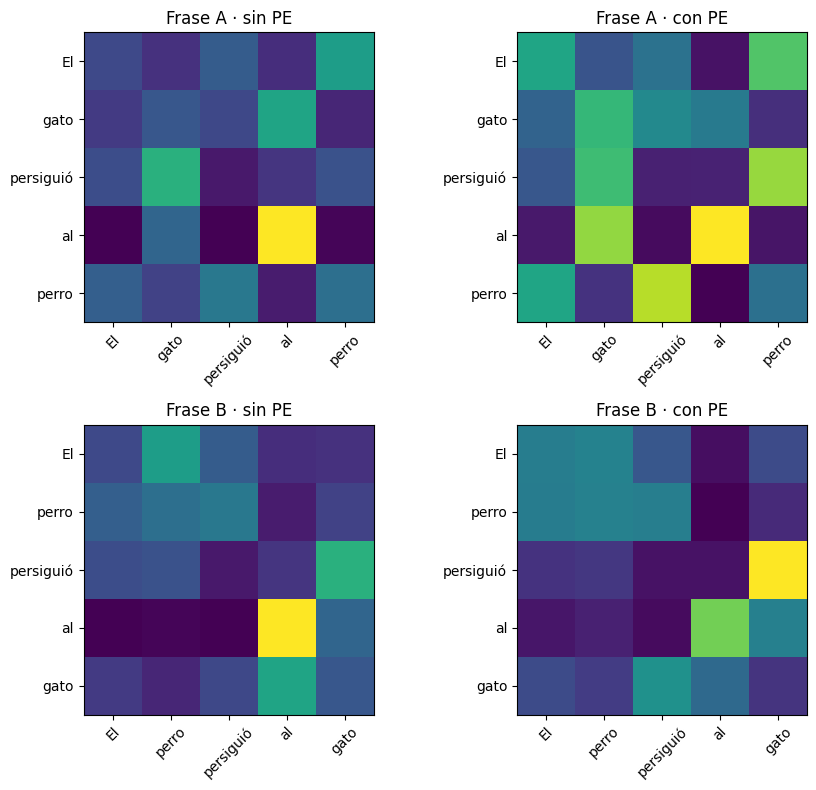

In [53]:
fig, ejes = plt.subplots(2, 2, figsize=(9, 8))
for r, (frase, nombre) in enumerate([(FRASE_A, "A"), (FRASE_B, "B")]):
    for c, usar_pe in enumerate((False, True)):
        _, att = ejecutar(frase, emb, capas, usar_pe)
        ejes[r, c].imshow(att[0].numpy(), cmap="viridis")
        ejes[r, c].set_xticks(range(len(frase)))
        ejes[r, c].set_yticks(range(len(frase)))
        ejes[r, c].set_xticklabels(frase, rotation=45)
        ejes[r, c].set_yticklabels(frase)
        ejes[r, c].set_title(f"Frase {nombre} · {'con PE' if usar_pe else 'sin PE'}")
fig.tight_layout()
plt.show()

## 2.8 · Visualización · Los embeddings de salida en 2D
Proyecto con PCA (SVD) las salidas de A y B juntas. Cada palabra de A es un círculo y de B una cruz. Sin PE, el círculo y la cruz de cada palabra se superponen: el modelo ve la misma "bolsa de palabras". Con PE se separan, sobre todo "gato" y "perro", que cambian de posición.

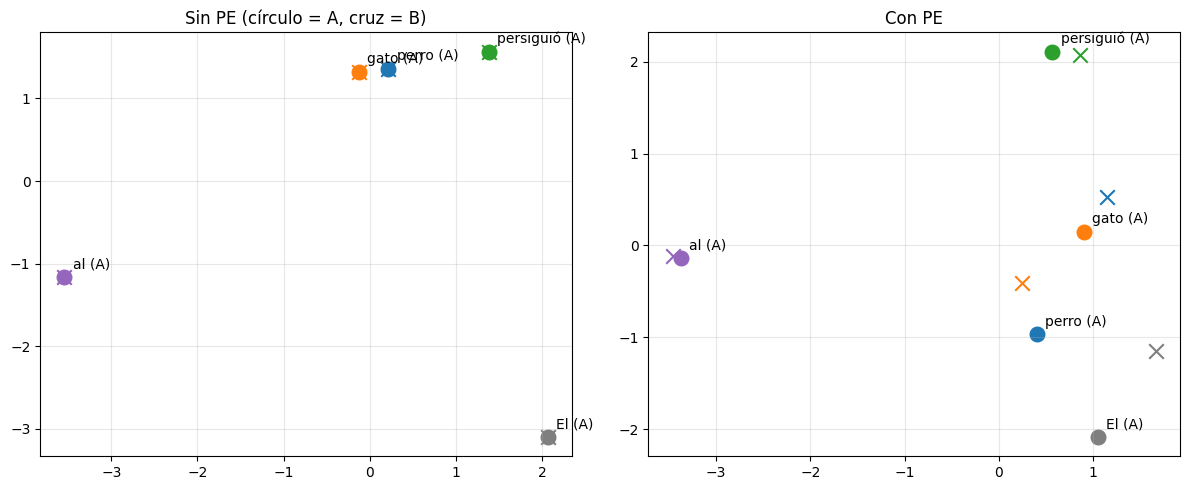

In [54]:
def proyectar(salidas):
    todo = torch.cat(salidas)
    centrado = todo - todo.mean(0)
    _, _, vt = torch.linalg.svd(centrado, full_matrices=False)
    return [(s - todo.mean(0)) @ vt[:2].T for s in salidas]


fig, ejes = plt.subplots(1, 2, figsize=(12, 5))
colores = {"El": "tab:gray", "gato": "tab:orange", "persiguió": "tab:green", "al": "tab:purple", "perro": "tab:blue"}
for ax, usar_pe in zip(ejes, (False, True)):
    sa, _ = ejecutar(FRASE_A, emb, capas, usar_pe)
    sb, _ = ejecutar(FRASE_B, emb, capas, usar_pe)
    pa, pb = proyectar([sa, sb])
    for i, w in enumerate(FRASE_A):
        ax.scatter(*pa[i], c=colores[w], marker="o", s=110)
        ax.annotate(f"{w} (A)", pa[i].tolist(), textcoords="offset points", xytext=(6, 6))
    for i, w in enumerate(FRASE_B):
        ax.scatter(*pb[i], c=colores[w], marker="x", s=110)
    ax.set_title("Con PE" if usar_pe else "Sin PE (círculo = A, cruz = B)")
    ax.grid(alpha=.3)
fig.tight_layout()
plt.show()

## 2.9 · Visualización · Cuánto cambia cada palabra
Barras con la distancia entre el vector de salida de cada palabra en A y en B (comparando la misma palabra, no la misma posición). Sin PE debería ser cero para todas; con PE, la diferencia es mayor en las palabras que cambiaron de lugar.

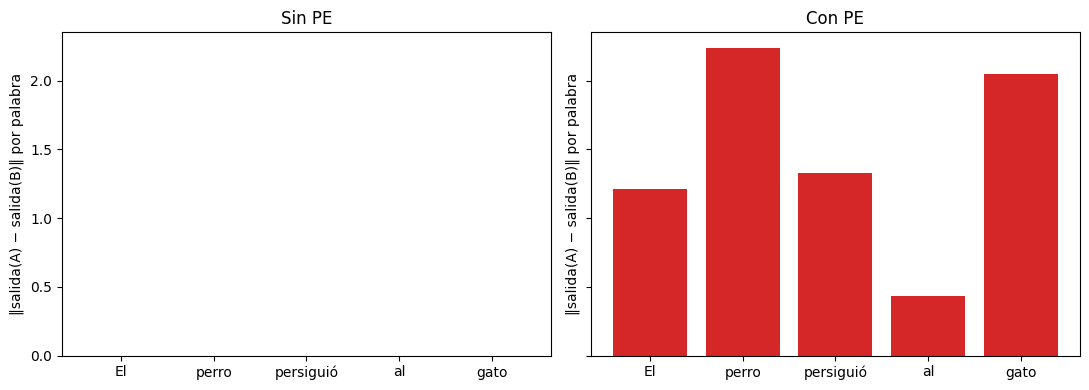

In [55]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, usar_pe in zip(ejes, (False, True)):
    sa, _ = ejecutar(FRASE_A, emb, capas, usar_pe)
    sb, _ = ejecutar(FRASE_B, emb, capas, usar_pe)
    dist = [(sa[PERM[j]] - sb[j]).norm().item() for j in range(len(FRASE_B))]
    ax.bar(FRASE_B, dist, color="tab:red" if usar_pe else "tab:blue")
    ax.set_title("Con PE" if usar_pe else "Sin PE")
    ax.set_ylabel("‖salida(A) − salida(B)‖ por palabra")
fig.tight_layout()
plt.show()

## 2.10 · Panel interactivo A (sliders)
Muevo la dimensión, el número de capas, la escala del embedding, la escala del PE y activo o desactivo el PE. La escala del embedding frente al PE importa: si el embedding es muy grande, el PE queda "tapado" y el modelo casi no nota el orden. En el título del gráfico aparece el error de equivarianza de la configuración elegida.

In [56]:
def panel(d, capas_n, escala_emb, escala_pe, usar_pe):
    e = crear_embeddings(FRASE_A, d, escala=escala_emb)
    c = crear_pesos(d, capas_n, SEMILLA)
    m = medir(FRASE_A, FRASE_B, e, c, usar_pe, escala_pe)
    _, atA = ejecutar(FRASE_A, e, c, usar_pe, escala_pe)
    _, atB = ejecutar(FRASE_B, e, c, usar_pe, escala_pe)
    fig, ejes = plt.subplots(1, 2, figsize=(10, 4.2))
    for ax, att, fr, n in zip(ejes, (atA[0], atB[0]), (FRASE_A, FRASE_B), "AB"):
        ax.imshow(att.numpy(), cmap="viridis")
        ax.set_xticks(range(5)); ax.set_yticks(range(5))
        ax.set_xticklabels(fr, rotation=45); ax.set_yticklabels(fr)
        ax.set_title(f"Atención capa 1 · frase {n}")
    fig.suptitle(f"{'CON' if usar_pe else 'SIN'} PE · error de equivarianza = {m['error_equivarianza']:.2e} · "
                 f"dif. de la frase = {m['dif_promedio_frase']:.2e}")
    fig.tight_layout()
    plt.show()


w_d = widgets.Dropdown(options=[8, 16, 32, 64], value=16, description="d")
w_c = widgets.IntSlider(value=2, min=1, max=6, description="capas")
w_e = widgets.FloatSlider(value=1.0, min=0.1, max=10.0, step=0.1, description="escala emb")
w_p = widgets.FloatSlider(value=1.0, min=0.0, max=5.0, step=0.1, description="escala PE")
w_u = widgets.Checkbox(value=True, description="usar PE")
salida = widgets.interactive_output(panel, {"d": w_d, "capas_n": w_c, "escala_emb": w_e, "escala_pe": w_p, "usar_pe": w_u})
display(widgets.VBox([widgets.HBox([w_d, w_c, w_u]), widgets.HBox([w_e, w_p]), salida]))

## 2.11 · Experimento A2 · Barrido de configuraciones
Repito la comparación con 4 dimensiones × 4 profundidades × 4 escalas de embedding (64 configuraciones), con y sin PE. Sin PE el error debe ser de orden 1e-15 en todas. Con PE depende de cuánto pesa el PE frente al embedding.

In [57]:
filas = []
for d, nc, esc in itertools.product([8, 16, 32, 64], [1, 2, 4, 6], [0.1, 1.0, 3.0, 10.0]):
    e = crear_embeddings(FRASE_A, d, escala=esc)
    c = crear_pesos(d, nc, SEMILLA)
    for usar_pe in (False, True):
        filas.append({"d": d, "capas": nc, "escala_emb": esc, "usar_pe": usar_pe, **medir(FRASE_A, FRASE_B, e, c, usar_pe)})
e2 = pd.DataFrame(filas)
display(e2.groupby("usar_pe").error_equivarianza.agg(["mean", "min", "max"]))

,mean,min,max
usar_pe,,,
False,1.693090e-15,4.440892e-16,4.746203e-15
True,8.010439e-01,4.940486e-02,2.283213e+00


## 2.12 · Mapa de calor: escala del embedding frente a escala del PE
Con 2 capas y d = 16, el error de equivarianza (con PE) para distintas escalas. La fila `escala PE = 0` es el caso sin PE.

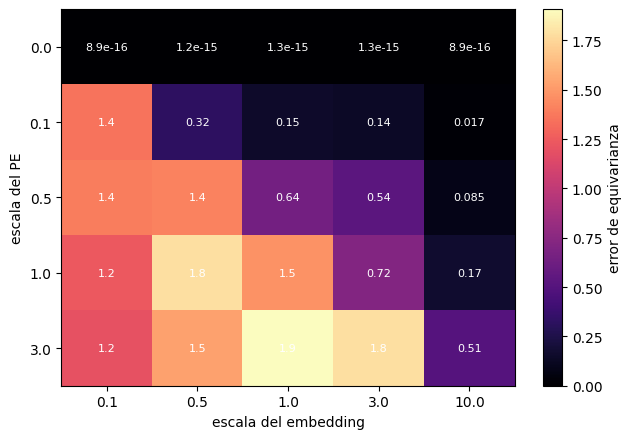

In [58]:
escalas_emb = [0.1, 0.5, 1.0, 3.0, 10.0]
escalas_pe = [0.0, 0.1, 0.5, 1.0, 3.0]
mapa = np.zeros((len(escalas_pe), len(escalas_emb)))
for i, sp in enumerate(escalas_pe):
    for j, se in enumerate(escalas_emb):
        e = crear_embeddings(FRASE_A, 16, escala=se)
        mapa[i, j] = medir(FRASE_A, FRASE_B, e, crear_pesos(16, 2, SEMILLA), sp > 0, sp)["error_equivarianza"]
plt.figure(figsize=(6.5, 4.5))
plt.imshow(mapa, cmap="magma", aspect="auto")
plt.colorbar(label="error de equivarianza")
plt.xticks(range(len(escalas_emb)), escalas_emb); plt.yticks(range(len(escalas_pe)), escalas_pe)
plt.xlabel("escala del embedding"); plt.ylabel("escala del PE")
for i in range(len(escalas_pe)):
    for j in range(len(escalas_emb)):
        plt.text(j, i, f"{mapa[i, j]:.2g}", ha="center", va="center", color="w", fontsize=8)
plt.tight_layout()
plt.show()

## 2.13 · Experimento A3 · Más frases y 100 permutaciones aleatorias
Para no depender de un solo par de frases, pruebo la consigna, una frase de 7 palabras y una con la palabra "gato" repetida. En cada una aplico 100 permutaciones aleatorias de las palabras y mido el error de equivarianza y la diferencia de la frase.

In [59]:
def experimento_permutaciones(frases, n_perm=100, semilla_perm=7):
    rng = np.random.default_rng(semilla_perm)
    filas = []
    for nombre, fr in frases.items():
        e = crear_embeddings(fr, D)
        for usar_pe in (False, True):
            errs, difs = [], []
            for _ in range(n_perm):
                perm = list(rng.permutation(len(fr)))
                sal, _ = ejecutar(fr, e, capas, usar_pe)
                sal_p, _ = ejecutar([fr[j] for j in perm], e, capas, usar_pe)
                errs.append((sal_p - sal[perm]).abs().max().item())
                difs.append((sal.mean(0) - sal_p.mean(0)).abs().max().item())
            filas.append({"frase": nombre, "n_tokens": len(fr), "usar_pe": usar_pe,
                          "err_eq_max": max(errs), "err_eq_media": float(np.mean(errs)),
                          "dif_frase_max": max(difs), "dif_frase_media": float(np.mean(difs))})
    return pd.DataFrame(filas)

In [60]:
e3 = experimento_permutaciones({"consigna": FRASE_A, **FRASES_EXTRA})
display(e3)

,frase,n_tokens,usar_pe,err_eq_max,err_eq_media,dif_frase_max,dif_frase_media
0,consigna,5,False,2.109424e-15,1.328816e-15,8.881784e-16,4.246603e-16
1,consigna,5,True,1.551370e+00,1.197078e+00,4.083995e-01,2.374201e-01
2,larga_7,7,False,1.554312e-15,1.154632e-15,6.661338e-16,3.542305e-16
3,larga_7,7,True,1.689260e+00,1.309678e+00,4.834473e-01,2.612638e-01
4,repetida,6,False,1.887379e-15,1.078027e-15,7.771561e-16,3.791065e-16
5,repetida,6,True,1.585611e+00,1.287685e+00,4.411122e-01,2.103689e-01


## 2.14 · Comparación con la referencia en NumPy
Antes de este notebook ejecuté el mismo experimento con una implementación independiente en NumPy (`codigo/referencia_numpy.py`). Aquí comparo las cifras de PyTorch con las que esa referencia guardó. Si coinciden, la implementación en PyTorch es correcta y el resultado no depende de la librería.

In [61]:
REF_E1_CON_PE = {"error_equivarianza": 1.4740524812860825, "dif_promedio_frase": 0.3611362015415375, "cos_gato_A_vs_B": 0.8685718234278538}
REF_E2 = {False: (1.680947048221526e-15, 1.0658141036401504e-14), True: (0.8010439362690127, 2.283213188372973)}
REF_E3_MEDIA_CON_PE = {"consigna": 1.1970777865842388, "larga_7": 1.3096775059216368, "repetida": 1.287684857867277}

for clave, valor in REF_E1_CON_PE.items():
    assert abs(con_pe[clave] - valor) < 1e-9, clave
for usar_pe, (media, maximo) in REF_E2.items():
    g = e2[e2.usar_pe == usar_pe].error_equivarianza
    if usar_pe:
        assert abs(g.mean() - media) < 1e-9 and abs(g.max() - maximo) < 1e-9
    else:
        assert g.max() < 1e-10 and maximo < 1e-10
for frase, valor in REF_E3_MEDIA_CON_PE.items():
    fila = e3[(e3.frase == frase) & e3.usar_pe].iloc[0]
    assert abs(fila.err_eq_media - valor) < 1e-9, frase
print("PyTorch coincide con la referencia NumPy (con PE a 1e-9; sin PE ambos del orden de 1e-15)")

PyTorch coincide con la referencia NumPy (con PE a 1e-9; sin PE ambos del orden de 1e-15)


## 2.15 · Chequeos de la Parte A
Cada afirmación de la Parte A con su valor de verdad calculado.

In [62]:
chequeos_A = pd.DataFrame([
    ("Sin PE, permutar la frase solo permuta la salida (error < 1e-10) en las 3 frases y 100 permutaciones", bool((e3[~e3.usar_pe].err_eq_max < 1e-10).all())),
    ("Sin PE, la media de las filas no distingue A de B (dif < 1e-10) en las 3 frases", bool((e3[~e3.usar_pe].dif_frase_max < 1e-10).all())),
    ("Con PE, el error de equivarianza medio supera 0.1 en las 3 frases", bool((e3[e3.usar_pe].err_eq_media > 0.1).all())),
    ("En las 64 configuraciones del barrido, sin PE el error es < 1e-10", bool((e2[~e2.usar_pe].error_equivarianza < 1e-10).all())),
    ("En las 64 configuraciones, con PE el error nunca llega a cero (mínimo > 0.01)", bool(e2[e2.usar_pe].error_equivarianza.min() > 0.01)),
    ("Con embedding de escala 10 el PE pesa menos: el error con PE es menor que con escala 1 (media de las 16 combinaciones de d y capas)",
     bool(e2[e2.usar_pe & (e2.escala_emb == 10.0)].error_equivarianza.mean() < e2[e2.usar_pe & (e2.escala_emb == 1.0)].error_equivarianza.mean())),
], columns=["afirmación", "verdadero"])
pd.set_option("display.max_colwidth", 200)
display(chequeos_A)

,afirmación,verdadero
0,"Sin PE, permutar la frase solo permuta la salida (error < 1e-10) en las 3 frases y 100 permutaciones",True
1,"Sin PE, la media de las filas no distingue A de B (dif < 1e-10) en las 3 frases",True
2,"Con PE, el error de equivarianza medio supera 0.1 en las 3 frases",True
3,"En las 64 configuraciones del barrido, sin PE el error es < 1e-10",True
4,"En las 64 configuraciones, con PE el error nunca llega a cero (mínimo > 0.01)",True
5,Con embedding de escala 10 el PE pesa menos: el error con PE es menor que con escala 1 (media de las 16 combinaciones de d y capas),True


# 3 · Parte B · Transformer entrenado con datos reales
La Parte A muestra la propiedad con pesos aleatorios. La Parte B pregunta si se mantiene cuando el modelo **aprende** de datos reales y qué dicen las fuentes sobre cuándo importa el PE.

## 3.1 · Metodología y de dónde sale cada decisión
| Decisión | Fuente |
| --- | --- |
| Mismo Transformer en todas las corridas; solo cambia el PE, y "sin PE" es el control | Guo (2024), ICEIB: modelos con la misma configuración base y NoPos como experimento de control |
| Comparar atención **bidireccional** (no causal) y **causal** | Zhang et al. (2024), ICASSP: el PE ayuda poco en configuración causal y mucho en la no causal; Hayakawa y Sato (2025), ACL: la máscara causal y un token de inicio permiten calcular la posición sin PE |
| Token de inicio `<BOS>` al comienzo de cada oración | Hayakawa y Sato (2025): el token de inicio es parte de su construcción |
| Una tarea donde el orden importa (**orden**: ¿la oración es original o tiene dos palabras intercambiadas?) y otra donde no (**idioma**: ¿español o inglés?) | Guo (2024): el PE importa en tareas donde el orden es crucial y menos en tareas semánticas (en sentimiento, NoPos rindió como RoPE) |
| Quitar el PE en evaluación a un modelo entrenado con PE (y un slider que lo escala) | Banđur et al. (2026), TPAMI: al quitar el PE sinusoidal la exactitud cae casi al azar |
| 3 semillas por configuración, media y desviación | Banđur et al. (2026) usan 3 semillas por método |

**Diseño:** 2 tareas × 2 tipos de atención × con/sin PE × 3 semillas = 24 entrenamientos. Modelo: d = 64, 2 capas, 4 cabezas, PE sinusoidal (la fórmula de la sección 2.1), promedio de los vectores de salida y una capa lineal.

## 3.2 · Librerías y parámetros de la Parte B
Paso a `float32` (la Parte A usa `float64` para comparar con NumPy) y uso GPU si Colab la asigna.

In [63]:
import collections
import io
import os
import random
import re
import time
import urllib.request
import zipfile

import torch.nn as nn

torch.set_default_dtype(torch.float32)
torch.set_num_threads(os.cpu_count() or 1)
DISP = torch.device("cuda" if torch.cuda.is_available() else "cpu")

URL_DATOS = "https://storage.googleapis.com/download.tensorflow.org/data/spa-eng.zip"
LARGO_MIN, LARGO_MAX = 4, 10      # palabras por oración
N_ORDEN, N_IDIOMA = 20000, 10000  # oraciones para cada tarea (idioma: 10 000 por lengua)
D_MODELO, CAPAS_B, CABEZAS = 64, 2, 4
EPOCAS, LOTE, LR = 8, 256, 2e-3
SEMILLAS = (0, 1, 2)
print("dispositivo:", DISP, "| hilos CPU:", torch.get_num_threads())

dispositivo: cuda | hilos CPU: 2


## 3.3 · Descarga del dataset
Uso el corpus español-inglés de **Tatoeba** en la versión de manythings.org/anki que TensorFlow aloja para su tutorial de traducción. Son pares de oraciones escritas por hablantes nativos o revisadas, con licencia CC-BY 2.0 (atribución: tatoeba.org y manythings.org/anki).

In [64]:
crudo = urllib.request.urlopen(URL_DATOS, timeout=60).read()
archivo_zip = zipfile.ZipFile(io.BytesIO(crudo))
lineas = archivo_zip.read("spa-eng/spa.txt").decode("utf-8").strip().split("\n")
print("archivos:", archivo_zip.namelist())
print("pares inglés-español:", len(lineas))
print("ejemplo:", lineas[60000])

archivos: ['spa-eng/', 'spa-eng/_about.txt', 'spa-eng/spa.txt']
pares inglés-español: 118964
ejemplo: Can you please leave me alone?	¿Me puedes dejar sola, por favor?


## 3.4 · Limpieza y tokenización
Paso a minúsculas, me quedo con las palabras (letras y tildes) y elimino oraciones repetidas. Conservo las de 4 a 10 palabras, la escala de la consigna.

In [65]:
def tokenizar(texto):
    return re.findall(r"[a-záéíóúüñ']+", texto.lower())


def oraciones_unicas(lineas, columna):
    unicas = {tuple(tokenizar(l.split("\t")[columna])) for l in lineas}
    return sorted(f for f in unicas if LARGO_MIN <= len(f) <= LARGO_MAX)

In [66]:
ORACIONES_ES = oraciones_unicas(lineas, 1)
ORACIONES_EN = oraciones_unicas(lineas, 0)
rng_datos = random.Random(0)
rng_datos.shuffle(ORACIONES_ES)
rng_datos.shuffle(ORACIONES_EN)
print("oraciones únicas de 4 a 10 palabras · español:", len(ORACIONES_ES), "| inglés:", len(ORACIONES_EN))

oraciones únicas de 4 a 10 palabras · español: 89363 | inglés: 86194


## 3.5 · Tarea de orden: dos palabras intercambiadas
Es la consigna llevada a miles de oraciones. A cada oración le asigno al azar la etiqueta 1 (se queda original) o 0 (intercambio dos palabras distintas, como "gato" y "perro"). Cada oración aparece una sola vez, así que la bolsa de palabras no revela la etiqueta: **solo el orden la revela**.

In [67]:
def intercambiar(frase, rng):
    pares = [(i, j) for i in range(len(frase)) for j in range(i + 1, len(frase)) if frase[i] != frase[j]]
    i, j = rng.choice(pares)
    f = list(frase)
    f[i], f[j] = f[j], f[i]
    return tuple(f)


def crear_tarea_orden(oraciones, semilla=1):
    rng = random.Random(semilla)
    ejemplos = []
    for f in oraciones:
        ejemplos.append((f, 1) if rng.random() < 0.5 else (intercambiar(f, rng), 0))
    return ejemplos

In [68]:
EJ_ORDEN = crear_tarea_orden(ORACIONES_ES[:N_ORDEN])
todas_es = set(ORACIONES_ES)
print("alteradas que coinciden con otra oración real del corpus:", sum(1 for f, y in EJ_ORDEN if y == 0 and f in todas_es))
for f, y in EJ_ORDEN[:6]:
    print(y, " ".join(f))

alteradas que coinciden con otra oración real del corpus: 0
1 pero qué enorme perro
0 él es un diplomático estadounidense la embajada de
1 costará al menos cinco dólares
1 pueden darme algo caliente de beber por favor
0 no podemos este ignorar problema
0 me no ya necesitas


## 3.6 · Tarea de control: identificar el idioma
10 000 oraciones en español (distintas de las de la tarea de orden) y 10 000 en inglés. Se resuelve mirando qué palabras aparecen; el orden no hace falta.

In [69]:
EJ_IDIOMA = [(f, 1) for f in ORACIONES_ES[N_ORDEN:N_ORDEN + N_IDIOMA]] + [(f, 0) for f in ORACIONES_EN[:N_IDIOMA]]
random.Random(2).shuffle(EJ_IDIOMA)
print("ejemplos:", len(EJ_IDIOMA))
for f, y in EJ_IDIOMA[:4]:
    print("es" if y else "en", " ".join(f))

ejemplos: 20000
en i'm going to teach you some karate
es él presume de que puede hablar seis lenguas
en tom wondered what mary was planning to do
es se convirtió al cristianismo


## 3.7 · División, vocabulario y tensores
80 % entrenamiento, 10 % validación y 10 % prueba. El vocabulario sale solo del entrenamiento (palabras con frecuencia ≥ 2). Índices especiales: 0 relleno, 1 `<BOS>` (token de inicio), 2 palabra desconocida.

In [70]:
def dividir(ejemplos):
    n = len(ejemplos)
    a, b = int(0.8 * n), int(0.9 * n)
    return ejemplos[:a], ejemplos[a:b], ejemplos[b:]


def vocabulario(entrenamiento, min_frec=2):
    cuenta = collections.Counter(w for f, _ in entrenamiento for w in f)
    return {w: i + 3 for i, w in enumerate(sorted(w for w, k in cuenta.items() if k >= min_frec))}


def tensorizar(ejemplos, voc):
    X = torch.zeros(len(ejemplos), LARGO_MAX + 1, dtype=torch.long)
    y = torch.tensor([e[1] for e in ejemplos])
    for k, (f, _) in enumerate(ejemplos):
        X[k, 0] = 1
        for p, w in enumerate(f):
            X[k, p + 1] = voc.get(w, 2)
    return X.to(DISP), y.to(DISP)

In [27]:
DATOS = {}
for nombre, ejemplos in (("orden", EJ_ORDEN), ("idioma", EJ_IDIOMA)):
    tr, va, te = dividir(ejemplos)
    voc = vocabulario(tr)
    DATOS[nombre] = {"voc": voc, "train": tensorizar(tr, voc), "val": tensorizar(va, voc), "test": tensorizar(te, voc)}
resumen_datos = pd.DataFrame([{"tarea": k, "train": len(v["train"][1]), "val": len(v["val"][1]), "test": len(v["test"][1]),
                               "vocabulario": len(v["voc"]) + 3, "proporción etiqueta 1 (train)": round(v["train"][1].float().mean().item(), 3)}
                              for k, v in DATOS.items()])
display(resumen_datos)

,tarea,train,val,test,vocabulario,proporción etiqueta 1 (train)
0,orden,16000,2000,2000,4680,0.507
1,idioma,16000,2000,2000,5220,0.500


## 3.8 · El clasificador
Embedding de palabras + PE sinusoidal opcional → `nn.TransformerEncoder` (Add & Norm después de cada subcapa, como la lámina 122) → promedio de los vectores (sin relleno) → capa lineal de 2 clases. Con `causal=True` cada posición solo atiende a las anteriores. `escala_pe` multiplica el PE en evaluación: 1 es normal y 0 lo quita.

In [28]:
class Clasificador(nn.Module):
    def __init__(self, n_vocab, usar_pe, causal, d=D_MODELO, capas=CAPAS_B, cabezas=CABEZAS):
        super().__init__()
        self.usar_pe, self.causal = usar_pe, causal
        self.emb = nn.Embedding(n_vocab, d, padding_idx=0)
        capa = nn.TransformerEncoderLayer(d, cabezas, 2 * d, dropout=0.1, batch_first=True)
        self.cod = nn.TransformerEncoder(capa, capas, enable_nested_tensor=False)
        self.salida = nn.Linear(d, 2)
        self.register_buffer("pe", pe_sinusoidal(LARGO_MAX + 1, d).float())

    def forward(self, x, escala_pe=1.0):
        relleno = x == 0
        L = x.shape[1]
        h = self.emb(x)
        if self.usar_pe:
            h = h + escala_pe * self.pe[:L]
        mascara = torch.triu(torch.ones(L, L, dtype=torch.bool, device=x.device), 1) if self.causal else None
        h = self.cod(h, mask=mascara, src_key_padding_mask=relleno)
        h = h.masked_fill(relleno[..., None], 0).sum(1) / (~relleno).sum(1, keepdim=True)
        return self.salida(h)

## 3.9 · Comprobación previa: sin PE y bidireccional, el modelo es invariante al orden
Antes de entrenar verifico la propiedad de la Parte A en este modelo: con un lote real, permuto las palabras (dejando `<BOS>` y el relleno en su lugar) y comparo las salidas. Sin PE y bidireccional deben ser iguales; con PE o con máscara causal deben cambiar.

In [29]:
@torch.no_grad()
def diferencia_por_permutacion(modelo, X, semilla=0):
    g = torch.Generator().manual_seed(semilla)
    Xp = X.clone()
    for k in range(len(X)):
        n = int((X[k] != 0).sum()) - 1
        idx = torch.randperm(n, generator=g) + 1
        Xp[k, 1:n + 1] = X[k, idx.to(X.device)]
    modelo.eval()
    return (modelo(X) - modelo(Xp)).abs().max().item()


X_prueba = DATOS["orden"]["val"][0][:256]
filas = []
for usar_pe in (False, True):
    for causal in (False, True):
        torch.manual_seed(0)
        m = Clasificador(len(DATOS["orden"]["voc"]) + 3, usar_pe, causal).to(DISP)
        filas.append({"pe": usar_pe, "atencion": "causal" if causal else "bidireccional",
                      "max |salida - salida permutada|": diferencia_por_permutacion(m, X_prueba)})
invarianza = pd.DataFrame(filas)
display(invarianza)

,pe,atencion,max |salida - salida permutada|
0,False,bidireccional,2.384186e-07
1,False,causal,3.520069e-01
2,True,bidireccional,1.033002e-01
3,True,causal,2.682516e-01


In [30]:
fila = invarianza[(~invarianza.pe) & (invarianza.atencion == "bidireccional")].iloc[0]
assert fila["max |salida - salida permutada|"] < 1e-4
assert (invarianza.drop(fila.name)["max |salida - salida permutada|"] > 1e-3).all()
print("Sin PE y bidireccional: invariante al orden. Con PE o con máscara causal: no.")

Sin PE y bidireccional: invariante al orden. Con PE o con máscara causal: no.


## 3.10 · Entrenamiento y evaluación
Adam, entropía cruzada, 8 épocas, lote 256. En cada época mido la exactitud en validación. Al final mido la exactitud en prueba y, si el modelo usa PE, también la exactitud **quitando el PE** en evaluación (ablación de Banđur et al., 2026).

In [31]:
@torch.no_grad()
def exactitud(modelo, datos, escala_pe=1.0):
    modelo.eval()
    X, y = datos
    return (modelo(X, escala_pe).argmax(1) == y).float().mean().item()


def entrenar(tarea, usar_pe, causal, semilla):
    torch.manual_seed(semilla)
    d = DATOS[tarea]
    modelo = Clasificador(len(d["voc"]) + 3, usar_pe, causal).to(DISP)
    opt = torch.optim.Adam(modelo.parameters(), lr=LR)
    X, y = d["train"]
    gen = torch.Generator().manual_seed(semilla)
    curva = []
    for ep in range(EPOCAS):
        modelo.train()
        orden = torch.randperm(len(y), generator=gen).to(DISP)
        total = 0.0
        for b in range(0, len(y), LOTE):
            i = orden[b:b + LOTE]
            perdida = F.cross_entropy(modelo(X[i]), y[i])
            opt.zero_grad()
            perdida.backward()
            opt.step()
            total += perdida.item() * len(i)
        curva.append({"epoca": ep + 1, "perdida": total / len(y), "acc_val": exactitud(modelo, d["val"])})
    resultado = {"tarea": tarea, "pe": usar_pe, "atencion": "causal" if causal else "bidireccional", "semilla": semilla,
                 "acc_test": exactitud(modelo, d["test"]),
                 "acc_test_quitando_pe": exactitud(modelo, d["test"], 0.0) if usar_pe else float("nan")}
    return resultado, curva, modelo

## 3.11 · Los 24 entrenamientos
Imprime una línea por entrenamiento. Con GPU tarda alrededor de un minuto y medio.

In [32]:
inicio = time.time()
filas, filas_curvas, MODELOS = [], [], {}
for tarea in ("orden", "idioma"):
    for causal in (False, True):
        for usar_pe in (False, True):
            for s in SEMILLAS:
                r, curva, modelo = entrenar(tarea, usar_pe, causal, s)
                filas.append(r)
                MODELOS[(tarea, r["atencion"], usar_pe, s)] = modelo
                filas_curvas += [{**c, "tarea": tarea, "atencion": r["atencion"], "pe": usar_pe, "semilla": s} for c in curva]
                quitando = f" · quitando PE {r['acc_test_quitando_pe']:.3f}" if usar_pe else ""
                print(f"{tarea:6s} {r['atencion']:13s} {'con PE' if usar_pe else 'sin PE'} semilla {s} · "
                      f"test {r['acc_test']:.3f}{quitando} · {time.time() - inicio:.0f} s")
resultados_B = pd.DataFrame(filas)
curvas_B = pd.DataFrame(filas_curvas)

orden  bidireccional sin PE semilla 0 · test 0.527 · 5 s
orden  bidireccional sin PE semilla 1 · test 0.501 · 9 s
orden  bidireccional sin PE semilla 2 · test 0.497 · 12 s
orden  bidireccional con PE semilla 0 · test 0.581 · quitando PE 0.516 · 15 s
orden  bidireccional con PE semilla 1 · test 0.585 · quitando PE 0.493 · 19 s
orden  bidireccional con PE semilla 2 · test 0.597 · quitando PE 0.488 · 23 s
orden  causal        sin PE semilla 0 · test 0.627 · 26 s
orden  causal        sin PE semilla 1 · test 0.616 · 30 s
orden  causal        sin PE semilla 2 · test 0.635 · 35 s
orden  causal        con PE semilla 0 · test 0.624 · quitando PE 0.604 · 38 s
orden  causal        con PE semilla 1 · test 0.622 · quitando PE 0.566 · 42 s
orden  causal        con PE semilla 2 · test 0.625 · quitando PE 0.562 · 46 s
idioma bidireccional sin PE semilla 0 · test 0.995 · 49 s
idioma bidireccional sin PE semilla 1 · test 0.996 · 53 s
idioma bidireccional sin PE semilla 2 · test 0.994 · 56 s
idioma bidir

## 3.12 · Tabla de resultados
Media y desviación estándar de las 3 semillas. El azar es 0.50 en ambas tareas.

In [33]:
tabla_B = (resultados_B.groupby(["tarea", "atencion", "pe"])[["acc_test", "acc_test_quitando_pe"]]
           .agg(["mean", "std"]).round(3))
display(tabla_B)

acc_test        acc_test_quitando_pe       
                               mean    std                 mean    std
tarea  atencion      pe                                               
idioma bidireccional False    0.995  0.001                  NaN    NaN
                     True     0.995  0.000                0.956  0.043
       causal        False    0.996  0.002                  NaN    NaN
                     True     0.996  0.001                0.962  0.033
orden  bidireccional False    0.508  0.016                  NaN    NaN
                     True     0.588  0.008                0.499  0.015
       causal        False    0.626  0.010                  NaN    NaN
                     True     0.623  0.002                0.577  0.023

## 3.13 · Gráfico · Exactitud en prueba por configuración
Barras con la media de las 3 semillas, puntos con cada semilla y la línea del azar.

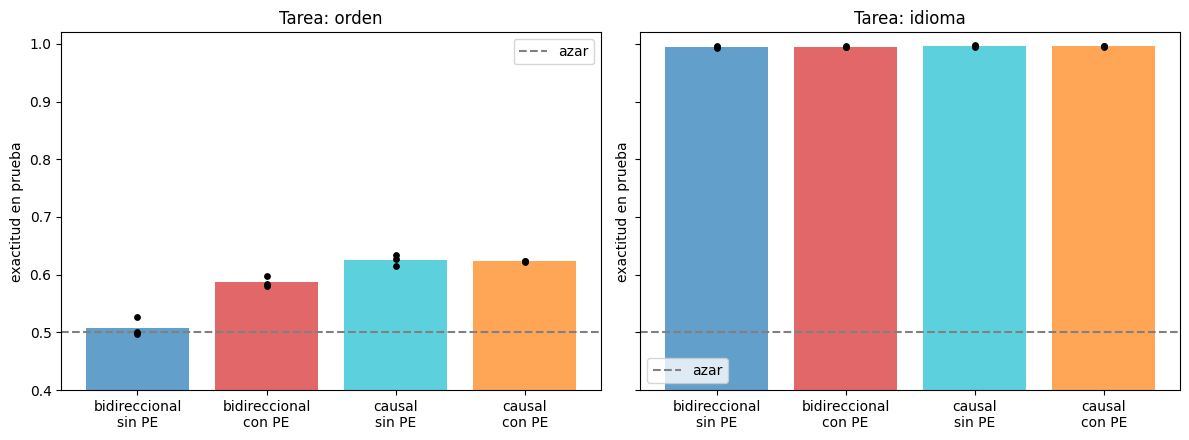

In [34]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, tarea in zip(ejes, ("orden", "idioma")):
    etiquetas, medias, puntos = [], [], []
    for at in ("bidireccional", "causal"):
        for pe in (False, True):
            v = resultados_B[(resultados_B.tarea == tarea) & (resultados_B.atencion == at) & (resultados_B.pe == pe)].acc_test
            etiquetas.append(f"{at}\n{'con PE' if pe else 'sin PE'}")
            medias.append(v.mean())
            puntos.append(v.values)
    colores = ["tab:blue", "tab:red", "tab:cyan", "tab:orange"]
    ax.bar(range(4), medias, color=colores, alpha=0.7)
    for k, p in enumerate(puntos):
        ax.scatter([k] * len(p), p, color="k", s=15, zorder=3)
    ax.axhline(0.5, ls="--", color="gray", label="azar")
    ax.set_xticks(range(4))
    ax.set_xticklabels(etiquetas)
    ax.set_title(f"Tarea: {tarea}")
    ax.set_ylim(0.4, 1.02)
    ax.set_ylabel("exactitud en prueba")
    ax.legend()
fig.tight_layout()
plt.show()

## 3.14 · Panel interactivo B1 · Curvas de validación (sliders)
Elijo la tarea, el tipo de atención y la semilla; el gráfico compara la exactitud de validación por época con y sin PE.

In [35]:
def panel_curvas(tarea, atencion, semilla):
    plt.figure(figsize=(7, 4))
    for pe, color in ((False, "tab:blue"), (True, "tab:red")):
        c = curvas_B[(curvas_B.tarea == tarea) & (curvas_B.atencion == atencion) & (curvas_B.pe == pe) & (curvas_B.semilla == semilla)]
        plt.plot(c.epoca, c.acc_val, marker="o", color=color, label="con PE" if pe else "sin PE")
    plt.axhline(0.5, ls="--", color="gray", label="azar")
    plt.ylim(0.4, 1.02)
    plt.xlabel("época")
    plt.ylabel("exactitud en validación")
    plt.title(f"{tarea} · {atencion} · semilla {semilla}")
    plt.legend()
    plt.show()


w_tarea = widgets.ToggleButtons(options=["orden", "idioma"], description="tarea")
w_aten = widgets.ToggleButtons(options=["bidireccional", "causal"], description="atención")
w_sem = widgets.IntSlider(value=0, min=0, max=len(SEMILLAS) - 1, description="semilla")
salida_curvas = widgets.interactive_output(panel_curvas, {"tarea": w_tarea, "atencion": w_aten, "semilla": w_sem})
display(widgets.VBox([w_tarea, w_aten, w_sem, salida_curvas]))

## 3.15 · Ablación del PE en evaluación
Tomo los modelos entrenados **con** PE y multiplico el PE por una escala entre 0 y 1 solo al evaluar. Con escala 0 el modelo pierde la información de posición que aprendió a usar.

In [36]:
ESCALAS = [0.0, 0.25, 0.5, 0.75, 1.0]
filas = []
for (tarea, at, pe, s), modelo in MODELOS.items():
    if pe:
        for e in ESCALAS:
            filas.append({"tarea": tarea, "atencion": at, "semilla": s, "escala_pe": e, "acc_test": exactitud(modelo, DATOS[tarea]["test"], e)})
ablacion_B = pd.DataFrame(filas)
display(ablacion_B.groupby(["tarea", "atencion", "escala_pe"]).acc_test.mean().unstack().round(3))

escala_pe              0.00   0.25   0.50   0.75   1.00
tarea  atencion                                        
idioma bidireccional  0.956  0.986  0.993  0.995  0.995
       causal         0.962  0.987  0.993  0.995  0.996
orden  bidireccional  0.499  0.525  0.549  0.573  0.588
       causal         0.577  0.594  0.611  0.619  0.623

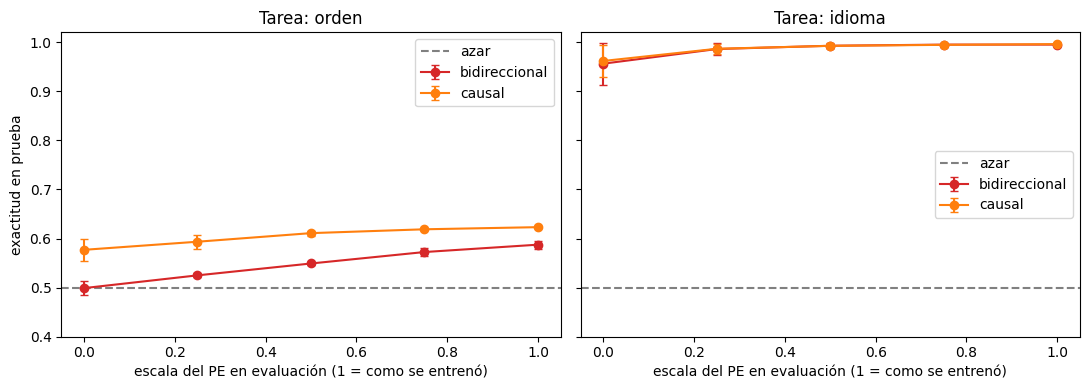

In [37]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, tarea in zip(ejes, ("orden", "idioma")):
    for at, color in (("bidireccional", "tab:red"), ("causal", "tab:orange")):
        g = ablacion_B[(ablacion_B.tarea == tarea) & (ablacion_B.atencion == at)].groupby("escala_pe").acc_test
        ax.errorbar(ESCALAS, g.mean(), yerr=g.std(), marker="o", color=color, capsize=3, label=at)
    ax.axhline(0.5, ls="--", color="gray", label="azar")
    ax.set_xlabel("escala del PE en evaluación (1 = como se entrenó)")
    ax.set_title(f"Tarea: {tarea}")
    ax.set_ylim(0.4, 1.02)
    ax.legend()
ejes[0].set_ylabel("exactitud en prueba")
fig.tight_layout()
plt.show()

## 3.16 · Panel interactivo B2 · Escala del PE en evaluación (slider)
Muevo la escala del PE con un slider y veo la exactitud del modelo elegido en el conjunto de prueba, calculada en el momento.

In [38]:
def panel_escala(tarea, atencion, semilla, escala):
    modelo = MODELOS[(tarea, atencion, True, semilla)]
    acc = exactitud(modelo, DATOS[tarea]["test"], escala)
    base = exactitud(modelo, DATOS[tarea]["test"], 1.0)
    plt.figure(figsize=(5, 3.5))
    plt.bar(["PE completo", f"PE × {escala:.2f}"], [base, acc], color=["tab:red", "tab:gray"])
    plt.axhline(0.5, ls="--", color="gray")
    plt.ylim(0.4, 1.02)
    plt.ylabel("exactitud en prueba")
    plt.title(f"{tarea} · {atencion} · semilla {semilla}")
    plt.show()


w_tarea2 = widgets.ToggleButtons(options=["orden", "idioma"], description="tarea")
w_aten2 = widgets.ToggleButtons(options=["bidireccional", "causal"], description="atención")
w_sem2 = widgets.IntSlider(value=0, min=0, max=len(SEMILLAS) - 1, description="semilla")
w_esc = widgets.FloatSlider(value=0.0, min=0.0, max=1.0, step=0.05, description="escala PE")
salida_escala = widgets.interactive_output(panel_escala, {"tarea": w_tarea2, "atencion": w_aten2, "semilla": w_sem2, "escala": w_esc})
display(widgets.VBox([w_tarea2, w_aten2, w_sem2, w_esc, salida_escala]))

## 3.17 · Panel interactivo B3 · Probar una oración propia
Escribo una oración en español; el panel muestra la probabilidad de "orden original" que dan los cuatro modelos de la tarea de orden (semilla elegida) para la oración y para su versión con dos palabras intercambiadas. Sin PE y bidireccional, las dos probabilidades son idénticas. Las palabras que no están en el vocabulario se tratan como desconocidas.

In [39]:
@torch.no_grad()
def prob_original(modelo, frase):
    X, _ = tensorizar([(tuple(frase), 1)], DATOS["orden"]["voc"])
    modelo.eval()
    return torch.softmax(modelo(X), 1)[0, 1].item()


def panel_oracion(texto, i, j, semilla):
    frase = tokenizar(texto)[:LARGO_MAX]
    if len(frase) < 2 or max(i, j) >= len(frase) or i == j:
        print("Escribe al menos 2 palabras y elige dos posiciones distintas dentro de la oración.")
        return
    alterada = list(frase)
    alterada[i], alterada[j] = alterada[j], alterada[i]
    print("original :", " ".join(frase))
    print("alterada :", " ".join(alterada))
    filas = []
    for at in ("bidireccional", "causal"):
        for pe in (False, True):
            m = MODELOS[("orden", at, pe, semilla)]
            filas.append({"modelo": f"{at} · {'con PE' if pe else 'sin PE'}",
                          "P(original | original)": round(prob_original(m, frase), 4),
                          "P(original | alterada)": round(prob_original(m, alterada), 4)})
    display(pd.DataFrame(filas))


w_texto = widgets.Text(value="el gato persiguió al perro", description="oración", continuous_update=False)
w_i = widgets.IntSlider(value=1, min=0, max=LARGO_MAX - 1, description="posición i")
w_j = widgets.IntSlider(value=4, min=0, max=LARGO_MAX - 1, description="posición j")
w_sem3 = widgets.IntSlider(value=0, min=0, max=len(SEMILLAS) - 1, description="semilla")
salida_oracion = widgets.interactive_output(panel_oracion, {"texto": w_texto, "i": w_i, "j": w_j, "semilla": w_sem3})
display(widgets.VBox([w_texto, widgets.HBox([w_i, w_j, w_sem3]), salida_oracion]))

## 3.18 · La consigna con los modelos entrenados: embeddings de salida con y sin PE
Vuelvo a la pregunta con los modelos **entrenados** en la tarea de orden. Paso "el gato persiguió al perro" y "el perro persiguió al gato", tomo los vectores de salida del codificador (uno por palabra, antes del promedio) y mido lo mismo que en la Parte A: el error de equivarianza y el coseno entre el "gato" de una frase y el de la otra. Luego los proyecto en 2D con PCA.

In [40]:
FRASE_A_B = tokenizar("El gato persiguió al perro")
FRASE_B_B = tokenizar("El perro persiguió al gato")


@torch.no_grad()
def vectores_salida(modelo, frase):
    X, _ = tensorizar([(tuple(frase), 1)], DATOS["orden"]["voc"])
    modelo.eval()
    relleno = X == 0
    L = X.shape[1]
    h = modelo.emb(X)
    if modelo.usar_pe:
        h = h + modelo.pe[:L]
    mascara = torch.triu(torch.ones(L, L, dtype=torch.bool, device=X.device), 1) if modelo.causal else None
    h = modelo.cod(h, mask=mascara, src_key_padding_mask=relleno)
    return h[0, 1:len(frase) + 1].cpu()

In [41]:
print("palabras fuera del vocabulario:", [w for w in FRASE_A_B if w not in DATOS["orden"]["voc"]])
perm_B = [FRASE_A_B.index(w) for w in FRASE_B_B]
filas = []
for at in ("bidireccional", "causal"):
    for pe in (False, True):
        for s in SEMILLAS:
            m = MODELOS[("orden", at, pe, s)]
            va, vb = vectores_salida(m, FRASE_A_B), vectores_salida(m, FRASE_B_B)
            filas.append({"atencion": at, "pe": pe, "semilla": s,
                          "error_equivarianza": (vb - va[perm_B]).abs().max().item(),
                          "cos_gato_A_vs_B": torch.nn.functional.cosine_similarity(va[1], vb[4], dim=0).item(),
                          "P(original) frase A": prob_original(m, FRASE_A_B), "P(original) frase B": prob_original(m, FRASE_B_B)})
consigna_B = pd.DataFrame(filas)
display(consigna_B.groupby(["atencion", "pe"])[["error_equivarianza", "cos_gato_A_vs_B", "P(original) frase A", "P(original) frase B"]].mean())

palabras fuera del vocabulario: ['persiguió']


error_equivarianza  cos_gato_A_vs_B  P(original) frase A  \
atencion      pe                                                                
bidireccional False        6.010135e-07         1.000000             0.462494   
              True         1.912029e+00         0.807912             0.567071   
causal        False        2.835802e+00         0.440614             0.812489   
              True         2.292097e+00         0.679161             0.741605   

                     P(original) frase B  
atencion      pe                          
bidireccional False             0.462494  
              True              0.469393  
causal        False             0.732730  
              True              0.633793

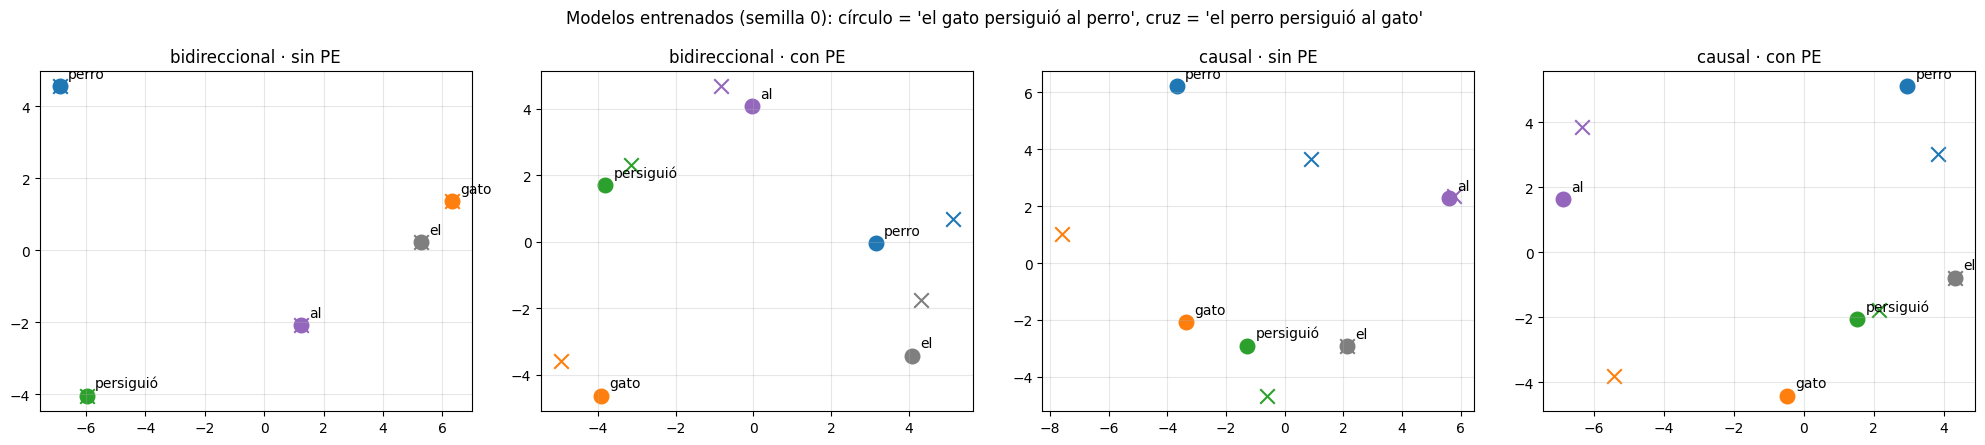

In [42]:
fig, ejes = plt.subplots(1, 4, figsize=(20, 4.5))
colores_B = {"el": "tab:gray", "gato": "tab:orange", "persiguió": "tab:green", "al": "tab:purple", "perro": "tab:blue"}
for ax, (at, pe) in zip(ejes, [("bidireccional", False), ("bidireccional", True), ("causal", False), ("causal", True)]):
    m = MODELOS[("orden", at, pe, 0)]
    va, vb = vectores_salida(m, FRASE_A_B), vectores_salida(m, FRASE_B_B)
    pa, pb = proyectar([va, vb])
    for i, w in enumerate(FRASE_A_B):
        ax.scatter(*pa[i], c=colores_B[w], marker="o", s=110)
        ax.annotate(w, pa[i].tolist(), textcoords="offset points", xytext=(6, 6))
    for i, w in enumerate(FRASE_B_B):
        ax.scatter(*pb[i], c=colores_B[w], marker="x", s=110)
    ax.set_title(f"{at} · {'con PE' if pe else 'sin PE'}")
    ax.grid(alpha=.3)
fig.suptitle("Modelos entrenados (semilla 0): círculo = 'el gato persiguió al perro', cruz = 'el perro persiguió al gato'")
fig.tight_layout()
plt.show()

# 4 · Chequeos de hipótesis de la Parte B
Cada predicción de la metodología, con la fuente que la motiva y su valor de verdad calculado con los 24 entrenamientos.

In [43]:
def media(tarea, at, pe, col="acc_test"):
    return resultados_B[(resultados_B.tarea == tarea) & (resultados_B.atencion == at) & (resultados_B.pe == pe)][col]


chequeos_B = pd.DataFrame([
    ("Orden, bidireccional sin PE: exactitud media dentro de 0.50 ± 0.03 (azar)", "Clase 12; Zhao et al. (2024)",
     bool(abs(media("orden", "bidireccional", False).mean() - 0.5) < 0.03)),
    ("Orden, bidireccional: con PE supera a sin PE en todas las semillas (mínimo con PE > máximo sin PE)", "Zhang et al. (2024): en no causal el PE ayuda",
     bool(media("orden", "bidireccional", True).min() > media("orden", "bidireccional", False).max())),
    ("Orden, causal sin PE: exactitud media > 0.55 (aprende posición sin PE)", "Zhang et al. (2024); Hayakawa y Sato (2025)",
     bool(media("orden", "causal", False).mean() > 0.55)),
    ("Orden, causal: con y sin PE difieren en menos de 0.02 (el PE ayuda poco)", "Zhang et al. (2024)",
     bool(abs(media("orden", "causal", True).mean() - media("orden", "causal", False).mean()) < 0.02)),
    ("Idioma, bidireccional: con y sin PE difieren en menos de 0.01", "Guo (2024)",
     bool(abs(media("idioma", "bidireccional", True).mean() - media("idioma", "bidireccional", False).mean()) < 0.01)),
    ("Orden, bidireccional con PE: al quitar el PE en evaluación la media cae por debajo de 0.53", "Banđur et al. (2026)",
     bool(media("orden", "bidireccional", True, "acc_test_quitando_pe").mean() < 0.53)),
    ("Consigna con el modelo entrenado bidireccional sin PE: error de equivarianza < 1e-4 en las 3 semillas", "Clase 12; Banđur et al. (2026)",
     bool((consigna_B[(consigna_B.atencion == "bidireccional") & ~consigna_B.pe].error_equivarianza < 1e-4).all())),
], columns=["afirmación", "fuente", "verdadero"])
display(chequeos_B)

,afirmación,fuente,verdadero
0,"Orden, bidireccional sin PE: exactitud media dentro de 0.50 ± 0.03 (azar)",Clase 12; Zhao et al. (2024),True
1,"Orden, bidireccional: con PE supera a sin PE en todas las semillas (mínimo con PE > máximo sin PE)",Zhang et al. (2024): en no causal el PE ayuda,True
2,"Orden, causal sin PE: exactitud media > 0.55 (aprende posición sin PE)",Zhang et al. (2024); Hayakawa y Sato (2025),True
3,"Orden, causal: con y sin PE difieren en menos de 0.02 (el PE ayuda poco)",Zhang et al. (2024),True
4,"Idioma, bidireccional: con y sin PE difieren en menos de 0.01",Guo (2024),True
5,"Orden, bidireccional con PE: al quitar el PE en evaluación la media cae por debajo de 0.53",Banđur et al. (2026),True
6,Consigna con el modelo entrenado bidireccional sin PE: error de equivarianza < 1e-4 en las 3 semillas,Clase 12; Banđur et al. (2026),True


# 5 · Fuentes y qué respaldan
Todas indexadas en IEEE Xplore o Scopus, de 2022 a 2026. Los PDF están en `fuentes/`.

| Afirmación o decisión | Fuente |
| --- | --- |
| Los Transformers son *position-agnostic*; la self-attention es invariante al reordenamiento y el PE permite distinguir el orden. En configuración no causal el PE ayuda mucho; en la causal, poco, porque la máscara causal no es invariante a permutaciones e inyecta posición de forma implícita | Zhang et al. (2024), ICASSP, pp. 1001-1005 (resumen p. 1001; máscara causal p. 1004). DOI 10.1109/ICASSP48485.2024.10446337 |
| Metodología: misma configuración base, solo cambia el PE, NoPos como control; el PE importa en tareas donde el orden es crucial y menos en las semánticas (en sentimiento, NoPos rindió como RoPE) | Guo (2024), ICEIB, pp. 246-250 (resumen p. 246; NoPos como control p. 247). DOI 10.1109/ICEIB61477.2024.10602658 |
| La self-attention es equivariante a permutaciones si no se le da información de posición; al quitar el PE sinusoidal la exactitud cae casi al azar; 3 semillas por método | Banđur, Banđur y Jakšić (2026), IEEE TPAMI, versión aceptada (equivarianza p. 1; quitar el PE p. 8). DOI 10.1109/TPAMI.2026.3736257 |
| Con máscara causal y un token de inicio, un Transformer sin PE puede calcular información de posición | Hayakawa y Sato (2025), ACL, pp. 30777-30834 (resumen p. 30777). DOI 10.18653/v1/2025.acl-long.1488 |
| Sin PE los Transformers son equivalentes a permutaciones (invariantes al orden); los modelos causales pueden aprender posición sin PE | Zhao et al. (2024), Findings of EMNLP, pp. 9959-9977 (p. 9960 y nota 2). DOI 10.18653/v1/2024.findings-emnlp.582 |

**Datos:** Tatoeba español-inglés (tatoeba.org, vía manythings.org/anki; licencia CC-BY 2.0), en la copia que aloja TensorFlow.

# 6 · Interpretación y límites
## 6.1 · Respuesta a la pregunta
**Sin Positional Encoding, el Transformer (el codificador bidireccional de la Clase 12) no distingue "El gato persiguió al perro" de "El perro persiguió al gato".** Cada palabra produce el mismo vector de salida en las dos frases; lo único que cambia es la fila en la que aparece. Si la salida se resume (por ejemplo, promediando para clasificar), las dos frases son idénticas para el modelo.

## 6.2 · La evidencia
- **Parte A · pesos aleatorios (2.5 a 2.13):** sin PE, el error de equivarianza es del orden de 1e-15 y el coseno entre el "gato" de una frase y el de la otra es 1.0; con PE el error sube a 1.47 y el coseno baja a 0.87. Lo mismo ocurre en 64 configuraciones y en 100 permutaciones de 3 frases. Las matrices de atención de las dos frases son la misma matriz con filas y columnas reordenadas, y en el PCA el círculo y la cruz de cada palabra se superponen.
- **Parte B · modelos entrenados con Tatoeba (3.18):** con las mismas dos frases, el modelo bidireccional sin PE da un error de equivarianza de 6e-7 (ruido de `float32`), coseno 1.0 para "gato" y la **misma** probabilidad de "orden original" para ambas frases (0.462). Con PE, el coseno baja a 0.81 y el modelo ya separa las frases (0.567 contra 0.469).
- **Tarea de orden con 2 000 oraciones de prueba (3.12):** el modelo bidireccional sin PE queda en el azar (0.508 ± 0.016) aunque se entrene; con PE sube a 0.588 ± 0.008. Si a ese modelo le quito el PE al evaluar, vuelve al azar (0.499), igual que el sinusoidal en Banđur et al. (2026).

## 6.3 · Por qué se pierde el orden
`Wq`, `Wk` y `Wv` son las mismas para todas las posiciones y el softmax trata a todas por igual: permutar la entrada solo permuta las filas y columnas de la matriz de atención, y la salida se permuta igual. La sección 3.9 lo confirma en el modelo de PyTorch antes de entrenar (diferencia de 2.4e-7 al permutar, contra 0.10 con PE). El orden solo entra si algo lo escribe en el vector de cada palabra: eso hace el PE (lámina 120).

## 6.4 · Matices que agregan las fuentes
- **La máscara causal también aporta orden.** El modelo causal **sin** PE supera al azar (0.626 ± 0.010) y el PE casi no le suma (0.623 ± 0.002), como encuentran Zhang et al. (2024) y como permite la construcción de Hayakawa y Sato (2025). La respuesta a la pregunta vale para el codificador bidireccional de la Clase 12, no para un decoder causal.
- **Si la tarea no depende del orden, el PE no aporta.** En identificar el idioma todos los modelos están en 0.995-0.996, como el análisis de sentimiento de Guo (2024). Aun así, a los modelos entrenados con PE quitarles el PE les baja la exactitud a 0.956-0.962: aprendieron a contar con él aunque no lo necesitaran.

## 6.5 · Límites
- La tarea de orden es difícil para un modelo tan pequeño (d = 64, 2 capas, 8 épocas): con PE llega a 0.59. Probé dos cambios que no mejoraron: entrenar 25 épocas (la validación se estancó cerca de 0.56-0.57) y clasificar con el vector de `<BOS>` en lugar del promedio (con PE bajó a 0.565; en el causal, leer la última palabra dio 0.610 sin PE y 0.636 con PE, la misma diferencia pequeña). Por eso mantuve el promedio. Lo que importa es la comparación entre configuraciones, no el valor absoluto.
- Un solo tipo de PE (sinusoidal), 3 semillas y un solo dataset. Dos ejecuciones en la misma GPU T4 dieron las mismas cifras, pero PyTorch no garantiza resultados idénticos en otro hardware.
- La Parte A usa pesos aleatorios: muestra una propiedad estructural, no rendimiento.

# 7 · Guardar resultados
Guardo las tablas de ambas partes como CSV y las comprimo para descargarlas.

In [44]:
e1.to_csv(CARPETA_SALIDA / "A_e1_consigna_torch.csv", index=False)
e2.to_csv(CARPETA_SALIDA / "A_e2_barrido_torch.csv", index=False)
e3.to_csv(CARPETA_SALIDA / "A_e3_permutaciones_torch.csv", index=False)
chequeos_A.to_csv(CARPETA_SALIDA / "A_chequeos_hipotesis.csv", index=False)
resumen_datos.to_csv(CARPETA_SALIDA / "B_resumen_datos.csv", index=False)
invarianza.to_csv(CARPETA_SALIDA / "B_invarianza_previa.csv", index=False)
resultados_B.to_csv(CARPETA_SALIDA / "B_resultados_por_semilla.csv", index=False)
curvas_B.to_csv(CARPETA_SALIDA / "B_curvas_validacion.csv", index=False)
ablacion_B.to_csv(CARPETA_SALIDA / "B_ablacion_pe.csv", index=False)
chequeos_B.to_csv(CARPETA_SALIDA / "B_chequeos_hipotesis.csv", index=False)
consigna_B.to_csv(CARPETA_SALIDA / "B_consigna_modelos_entrenados.csv", index=False)
print(sorted(p.name for p in CARPETA_SALIDA.iterdir()))

['A_chequeos_hipotesis.csv', 'A_e1_consigna_torch.csv', 'A_e2_barrido_torch.csv', 'A_e3_permutaciones_torch.csv', 'B_ablacion_pe.csv', 'B_chequeos_hipotesis.csv', 'B_consigna_modelos_entrenados.csv', 'B_curvas_validacion.csv', 'B_invarianza_previa.csv', 'B_resultados_por_semilla.csv', 'B_resumen_datos.csv', 'chequeos_hipotesis_torch.csv', 'e1_consigna_torch.csv', 'e2_barrido_torch.csv', 'e3_permutaciones_torch.csv']


In [71]:
import shutil
shutil.make_archive("resultados_s13", "zip", CARPETA_SALIDA)
try:
    from google.colab import files
    files.download("resultados_s13.zip")
except ImportError:
    print("Fuera de Colab: el zip quedó en el directorio actual")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>